# Ancient Environmental Metagenomics (AEMG01)
## Day 1 · Practical: Quality control, adapter trimming, read merging and host DNA removal

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day1_QC_shortcut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisite:** you have run **`Day1_setup_shortcut.ipynb`** once (shortcut to the shared folder, repository cloned, data copied to `01_DATA`).

### Learning outcomes
After this practical you will be able to:

* explain **why** pre-processing is especially critical for ancient DNA (aDNA),
* run and interpret **FastQC / MultiQC** quality reports,
* remove **sequencing adapters** and low-quality bases with **cutadapt**, and filter reads by length,
* **merge overlapping paired-end reads** and remove **poly-G tails** with **fastp**,
* remove **host (human) DNA** by aligning to the human reference genome with **Bowtie2** and extracting the unmapped reads with **samtools**,
* inspect alignments interactively in **IGV** directly in the notebook,
* keep track of how many reads survive each filtering step.

<p align="center">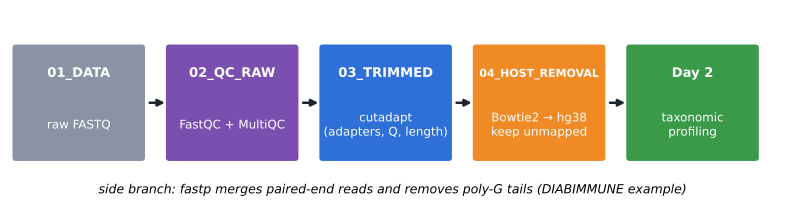<br><em>Today's workflow. Each step writes into its own numbered folder inside your Drive.</em></p>

---
## Scientific background: why is pre-processing so important for ancient DNA?

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/metagenomic_approaches.png" width="700"><br><em>The three ways to find out 'who is there' in a metagenome: alignment, k-mer classification and de-novo assembly. All of them assume clean, adapter-free, host-free reads.</em></p>

Ancient environmental DNA (sediments, permafrost, dental calculus, coprolites, bones) differs from modern DNA in ways that directly affect pre-processing:

1. **Short fragments.** After an organism dies, its DNA is broken down by nucleases and by chemical processes (hydrolysis, depurination). Authentic aDNA molecules are typically **30–70 bp** long. Illumina instruments sequence a fixed number of cycles (e.g. 75, 100 or 150), so the sequencer usually reads **past the end** of the short molecule **into the adapter** (*adapter read-through*, figure below). Untrimmed adapters make reads unalignable or – worse – cause them to hit the wrong reference.
2. **Damage.** Cytosines at single-stranded molecule ends become deaminated to uracils, which are read as **C→T** (5′ end) and **G→A** (3′ end). This is our best signal of authenticity (Day 3), so pre-processing **must not remove it** – e.g. we do not "error-correct" read ends aggressively.
3. **Low endogenous content & contamination.** Most DNA in a sample may be modern (lab reagents, people handling the sample, modern soil microbes). The **human** DNA in particular must be removed – scientifically (it is contamination for an environmental study) and ethically (human reads are personal genetic data).
4. **Very short reads are dangerous.** The shorter a read, the more genomes it matches by chance. A minimum length filter (here **30 bp**) is a compromise between keeping the shortest authentic aDNA molecules and avoiding spurious hits.

<p align="center">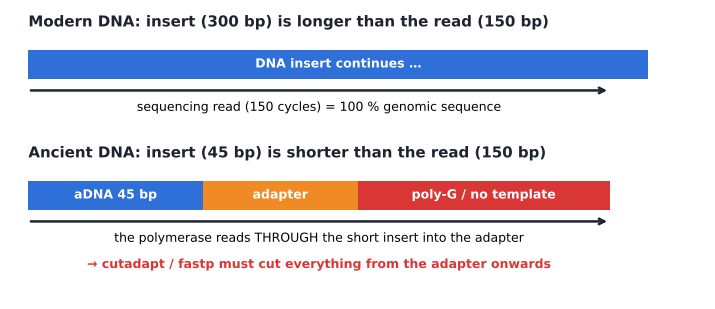<br><em>Adapter read-through: the shorter the DNA molecule, the larger the fraction of the read that is adapter (and, on two-colour instruments, poly-G).</em></p>

---
## 1. Session setup

Every notebook starts on a **fresh Colab machine**, so we (1) install conda, (2) mount Google Drive, (3) install today's software, (4) set paths and helper functions. This takes ~5 minutes.

### 1.1 Install conda

`condacolab.install()` installs Miniforge (conda + mamba) and **restarts the kernel**. The *"session crashed"* message is expected – just continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

In [ ]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

### 1.2 Mount Google Drive

Your working folder `AEMG01` (where all results are written) and the shortcut to the shared course folder (read only) live in your Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### 1.3 Install today's software

| Tool | What we use it for |
|---|---|
| [FastQC](https://www.bioinformatics.babraham.ac.uk/projects/fastqc) | quality report for each FASTQ file |
| [MultiQC](https://multiqc.info/) | combines many FastQC (and other) reports into one interactive report |
| [cutadapt](https://cutadapt.readthedocs.io/) | adapter trimming, quality trimming, length filtering |
| [fastp](https://github.com/OpenGene/fastp) | all-in-one trimming, **paired-end read merging**, **poly-G** trimming |
| [Bowtie2](https://bowtie-bio.sourceforge.net/bowtie2/) | aligning reads to the human reference genome |
| [samtools](http://www.htslib.org/) | manipulating alignments (BAM files) |
| [igv-notebook](https://github.com/igvteam/igv-notebook) | the IGV genome browser embedded in the notebook |

`mamba install -y -q -c conda-forge -c bioconda …` installs the command-line tools from Bioconda (`-y` no confirmation prompt, `-q` quiet, `-c` channels in priority order). `igv-notebook` is a Python package, so we install it with `pip`. Output is redirected to a log file (`> file 2>&1`) to keep the notebook tidy; look at `/content/install.log` if something fails.

In [ ]:
!mamba install -y -q -c conda-forge -c bioconda fastqc multiqc cutadapt fastp bowtie2 samtools > /content/install.log 2>&1
!pip install -q igv-notebook

Always record **software versions** – results can change between versions and reviewers will ask for them in your Methods section.

In [ ]:
%%bash
fastqc --version
multiqc --version
echo "cutadapt $(cutadapt --version)"
fastp --version 2>&1
bowtie2 --version | head -1
samtools --version | head -1

### 1.4 Paths, threads and helper functions

We read the location of the shared course folder from `course_paths.json` (written by `Day1_setup_shortcut.ipynb`) and export the paths as environment variables so that every `%%bash` cell can use them:

* `$WORKDIR` – your working folder in Drive (all results are written here),
* `$SHARE` – the shortcut to the instructor's shared folder (read-only inputs),
* `$HG38_INDEX` – prefix of the pre-built Bowtie2 index of the human genome; the cell **searches** the shared folder for it (index files end in `.1.bt2l`/`.1.bt2`; the prefix is the file name without that ending), so it works whether the index is in `Databases/hg38/` or directly in `hg38/`,
* `$THREADS` – number of CPU cores of this Colab machine.

In [ ]:
import os, json, glob
WORKDIR = "/content/drive/MyDrive/AEMG01"            # your own working folder (Day1_setup)
paths = json.load(open(f"{WORKDIR}/course_paths.json"))
SHARE = paths["SHARE"]
# find the hg38 Bowtie2 index anywhere in the shared folder (e.g. Databases/hg38/ or hg38/)
idx = sorted(glob.glob(f"{SHARE}/*/*.1.bt2l") + glob.glob(f"{SHARE}/*/*/*.1.bt2l") +
             glob.glob(f"{SHARE}/*/*.1.bt2")  + glob.glob(f"{SHARE}/*/*/*.1.bt2"))
idx = [i for i in idx if "hg38" in i]
HG38_INDEX = idx[0].rsplit(".1.bt2", 1)[0] if idx else None      # index prefix, e.g. …/hg38.fa.gz

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, HG38_INDEX=str(HG38_INDEX),
                  THREADS=str(os.cpu_count()))
os.chdir(WORKDIR)

print("WORKDIR   :", WORKDIR)
print("SHARE     :", SHARE)
print("THREADS   :", os.environ["THREADS"])
print("HG38_INDEX:", HG38_INDEX or "❌ not found – set HG38_INDEX to the index prefix by hand")
print("samples   :", open("SAMPLES.txt").read().split())

**Displaying HTML reports inside the notebook.** FastQC, MultiQC and fastp produce interactive HTML reports. In the cloud we cannot simply double-click them, so we define two helpers:

* `show_html(path)` – starts a tiny web server (`python -m http.server`) in your working folder **once**, and uses Colab's `serve_kernel_port_as_iframe` to show the report in an embedded frame. This keeps all the JavaScript interactivity of MultiQC.
* `download(path)` – downloads the file to your own computer, to open it in your browser.

> Embedded reports are only visible while the Colab session is running; they are not saved inside the notebook.

In [ ]:
import subprocess, socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown

PORT = 8000

def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_html(path, height=800):
    """Show an HTML report (path relative to WORKDIR) in an interactive iframe."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", WORKDIR],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + path, height=height)

def download(path):
    files.download(path)

print("Helpers ready: show_html(), download()")

---
## 2. Quality control of the raw data

### Background
Sequencing is subject to several types of problems that introduce errors and artefacts: base-calling errors that increase along the read, adapter read-through, over-represented sequences (adapter dimers, PCR duplicates), and biased base composition. Bioinformatics analyses therefore start with **quality control (QC)** of the raw reads.

[**FastQC**](https://www.bioinformatics.babraham.ac.uk/projects/fastqc) runs a set of checks ("modules") on each FASTQ file. The most informative modules for aDNA are:

| FastQC module | What to look for in aDNA data |
|---|---|
| **Per base sequence quality** | Quality typically drops towards the 3′ end of the read. Green zone = Q > 28, orange = Q 20–28, red = Q < 20. |
| **Adapter content** | Expect **a lot** of adapter in raw aDNA data, rising along the read, because molecules are short. |
| **Sequence length distribution** | Raw reads all have the same length (number of cycles); after trimming this becomes the *molecule* length distribution. |
| **Per base sequence content** | Odd composition at read ends can reflect adapters, poly-G tails or – in aDNA – damage and fragmentation biases. |
| **Sequence duplication / over-represented sequences** | Adapter dimers and PCR duplicates; low-complexity libraries (typical for aDNA) show high duplication. |

> ⚠️ FastQC's "PASS/WARN/FAIL" thresholds were designed for modern genomic data. A "FAIL" for adapter content or duplication is **expected** for aDNA – interpret, don't panic!

[**MultiQC**](https://multiqc.info/) collects the FastQC results of all samples into **one** report, so that samples can be compared side-by-side.

### Run FastQC and MultiQC

* `mkdir -p 02_QC_RAW` – folder for the reports,
* `fastqc 01_DATA/*.fastq.gz` – run FastQC on all raw files (the shell expands `*` to the full list),
* `--outdir 02_QC_RAW` – the **output** folder for the reports (short form `-o`),
* `-t $THREADS` – number of files processed in parallel (**t**hreads),
* `multiqc 02_QC_RAW` – scan this folder for any reports MultiQC recognises,
* `-o 02_QC_RAW` – (for MultiQC) where to write `multiqc_report.html` and the `multiqc_data/` folder,
* `--interactive` – use interactive (zoomable, hover-able) plots even for many samples.

In [ ]:
%%bash
cd "$WORKDIR"
mkdir -p 02_QC_RAW
fastqc 01_DATA/*.fastq.gz --outdir 02_QC_RAW -t $THREADS --quiet
multiqc 02_QC_RAW -o 02_QC_RAW --interactive --force
ls 02_QC_RAW

`--force` overwrites an old MultiQC report if you re-run the cell (otherwise MultiQC would create `multiqc_report_1.html`). `--quiet` makes FastQC print only errors.

Now let's open the MultiQC report **inside the notebook**. We will go through it together before continuing.

In [ ]:
show_html("02_QC_RAW/multiqc_report.html", height=900)

You can also open the FastQC report of a single sample the same way, or download a report to open it in your own browser:

In [ ]:
show_html("02_QC_RAW/sample1_fastqc.html", height=800)
# download("02_QC_RAW/multiqc_report.html")   # uncomment to download

The numbers behind the MultiQC "General Statistics" table are also saved as a text file, which we can load with pandas:

In [ ]:
import pandas as pd
gs = pd.read_csv("02_QC_RAW/multiqc_data/multiqc_general_stats.txt", sep="\t")
gs

❓ **Questions**
1. In which part of the reads does the base quality drop?
2. What percentage of reads contain adapter sequence, and how does adapter content change along the read? What does this tell you about the length of the DNA molecules?
3. Which FastQC modules show WARN/FAIL? Which of them are *expected* for ancient DNA?

---
## 3. Adapter and quality trimming with cutadapt

### Background
The QC report showed that a large fraction of reads contain adapters – exactly what we expect for short aDNA molecules. Before any downstream analysis we must **trim** the reads. Three things happen in one pass:

1. **Adapter removal.** cutadapt searches each read for the adapter sequence, allowing a small error rate (10 % by default) and **partial** matches at the 3′ end (a read may end with just the first few bases of the adapter). Everything from the start of the adapter to the end of the read is removed. `AGATCGGAAGAG` are the first 12 bases shared by the Illumina TruSeq adapters of both reads (for Nextera libraries it would be `CTGTCTCTTATA`).
2. **Quality trimming.** Low-quality bases are removed from the 3′ end with the BWA algorithm: cutadapt finds the cut position that maximises the sum of `(quality − threshold)` over the trimmed tail, so isolated good bases don't stop the trimming.
3. **Length filtering.** Reads that became too short after trimming are discarded.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/carpio.png" width="650"><br><em>What happens if adapters are not removed: the carp (Cyprinus carpio) reference genome in NCBI contains Illumina adapter sequence, so untrimmed reads 'find' a carp in your sediment and may suggest a lake or a river that never existed.</em></p>

### The command, explained flag by flag

```bash
for sample in $(cat SAMPLES.txt); do
  cutadapt 01_DATA/${sample}.fastq.gz \
           -o 03_TRIMMED/${sample}.trimmed.fastq.gz \
           -a AGATCGGAAGAG \
           -m 30 \
           -q 20 \
           -j $THREADS > 03_TRIMMED/${sample}.log
done
```

| Part | Meaning |
|---|---|
| `for sample in $(cat SAMPLES.txt); do … done` | a bash **for loop**: `$(cat SAMPLES.txt)` is replaced by the list of sample names, and the body runs once per name with the variable `$sample` set (`${sample}` = same thing, with braces to mark where the name ends) |
| `01_DATA/${sample}.fastq.gz` | the input reads (cutadapt reads gzipped files directly) |
| `-o …trimmed.fastq.gz` | **o**utput file; the `.gz` ending makes cutadapt compress it |
| `-a AGATCGGAAGAG` | the 3′ **a**dapter to remove |
| `-m 30` | **m**inimum length: discard reads shorter than 30 bp after trimming |
| `-q 20` | **q**uality-trim the 3′ end at Phred 20 (= 1 % error probability) |
| `-j $THREADS` | number of CPU cores (**j**obs); `-j 0` = autodetect |
| `> 03_TRIMMED/${sample}.log` | **redirect** the report that cutadapt prints to the screen (*standard output*) into a log file, so we can read it later |
| `\` at the end of a line | "the command continues on the next line" – purely for readability |

In [ ]:
%%bash
cd "$WORKDIR"
mkdir -p 03_TRIMMED

for sample in $(cat SAMPLES.txt); do
  echo "Trimming ${sample} ..."
  cutadapt 01_DATA/${sample}.fastq.gz \
           -o 03_TRIMMED/${sample}.trimmed.fastq.gz \
           -a AGATCGGAAGAG \
           -m 30 \
           -q 20 \
           -j $THREADS > 03_TRIMMED/${sample}.log
done
ls -lh 03_TRIMMED

❓ **Questions** (use `cutadapt --help` or the [online manual](https://cutadapt.readthedocs.io/en/stable/guide.html))
1. What do the `-o`, `-a`, `-m`, `-q` and `-j` flags mean?
2. How did we choose the values for `-m` and `-q`?
3. What is the purpose of the redirection `> 03_TRIMMED/${sample}.log`?

<details><summary><b>Click to see the answers</b></summary>

1. See the table above.
2. **`-q 20`** is the conventional threshold of 1 % error probability per base: stricter values (Q30) remove a lot of data from already scarce aDNA libraries; laxer ones keep many errors which look like mismatches (or even like damage!). **`-m 30`** is a compromise: aDNA molecules can be very short, but reads below ~30 bp match many genomes by chance and produce false-positive hits. Note that k-mer classifiers such as KrakenUniq (Day 2) use **k = 31** by default, so a read must be at least 31 bp long to contain a single k-mer – many aDNA pipelines therefore use a minimum length of 30–35 bp.
3. cutadapt writes its trimming report to standard output. Without the redirection the report would scroll by on the screen and be lost; with it we keep a permanent per-sample record that we can parse (next cell) and report in a paper.
</details>

### Reading the cutadapt logs

Let's look at one log. `cat` prints a whole file; `head -n 40` limits it to the first 40 lines (the summary section). In a terminal you would use `less` (scroll with arrow keys / space, quit with `q`), but `less` is interactive and does not work in notebook cells.

In [ ]:
%%bash
cd "$WORKDIR"
head -n 40 03_TRIMMED/sample1.log

Reading ten logs by eye is tedious and error-prone, so let's **parse all logs into a table** with Python. We use *regular expressions* (`re.search`) to find the numbers after each label, and remove the thousands separators (`,`) before converting to integers.

> Note: our simulated data are **single-end**, so cutadapt reports *reads*, not *read pairs*.

In [ ]:
import re

def grab(pattern, text, cast=int):
    m = re.search(pattern, text)
    return cast(m.group(1).replace(",", "")) if m else None

rows = []
for sample in open("SAMPLES.txt").read().split():
    txt = open(f"03_TRIMMED/{sample}.log").read()
    rows.append({
        "sample": sample,
        "reads_in":           grab(r"Total reads processed:\s+([\d,]+)", txt),
        "with_adapter":       grab(r"Reads with adapters:\s+([\d,]+)", txt),
        "too_short":          grab(r"Reads that were too short:\s+([\d,]+)", txt),
        "reads_out":          grab(r"Reads written \(passing filters\):\s+([\d,]+)", txt),
        "bp_quality_trimmed": grab(r"Quality-trimmed:\s+([\d,]+) bp", txt),
        "pct_bp_kept":        grab(r"Total written \(filtered\):\s+[\d,]+ bp \(([\d.]+)%\)", txt, float),
    })
cut = pd.DataFrame(rows).set_index("sample")
cut["pct_with_adapter"] = (100 * cut.with_adapter / cut.reads_in).round(1)
cut["pct_reads_kept"]   = (100 * cut.reads_out / cut.reads_in).round(1)
cut

❓ **Questions** – answer from the table above:
1. How many reads did each sample have originally?
2. How many (and what percentage of) reads contained adapters?
3. How many reads were removed because they were too short?
4. How many base calls were quality-trimmed?
5. Overall, what percentage of base pairs was kept?

### Read lengths before vs after trimming

This is the most "ancient" plot of today. Raw reads all have the same length (the number of sequencing cycles). After the adapters are cut off, the read length equals the length of the original **DNA molecule** – and for aDNA we expect a distribution concentrated at **short** lengths (mode around 30–70 bp). Modern contaminant DNA, by contrast, gives long reads that are rarely adapter-trimmed.

In [ ]:
import gzip, numpy as np, matplotlib.pyplot as plt

def read_lengths(path, n=200_000):
    lengths = []
    with gzip.open(path, "rt") as f:
        for i, line in enumerate(f):
            if i % 4 == 1:
                lengths.append(len(line.strip()))
                if len(lengths) >= n:
                    break
    return np.array(lengths)

sample = "sample10"
raw  = read_lengths(f"01_DATA/{sample}.fastq.gz")
trim = read_lengths(f"03_TRIMMED/{sample}.trimmed.fastq.gz")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
ax[0].hist(raw,  bins=range(0, raw.max() + 2),  color="#8A93A3"); ax[0].set_title(f"{sample}: raw reads")
ax[1].hist(trim, bins=range(0, trim.max() + 2), color="#2E6FD8"); ax[1].set_title(f"{sample}: after cutadapt")
for a in ax:
    a.set_xlabel("Read length (bp)"); a.set_ylabel("Number of reads")
ax[1].axvline(30, color="#D93636", ls="--"); ax[1].text(31, ax[1].get_ylim()[1]*0.9, "-m 30", color="#D93636")
plt.tight_layout(); plt.show()
print(f"median length after trimming: {np.median(trim):.0f} bp")

❓ Change `sample` to another sample and re-run. Do all samples have the same fragment-length distribution? Why is there a sharp edge at 30 bp?

### QC of the trimmed data

Now that the data are trimmed it's a good idea to run FastQC and MultiQC again – this is the **modification of the raw-data commands** asked for in the original exercise: only the input files and the output folder change.

In [ ]:
%%bash
cd "$WORKDIR"
mkdir -p 03_TRIMMED/QC
fastqc 03_TRIMMED/*.trimmed.fastq.gz --outdir 03_TRIMMED/QC -t $THREADS --quiet
multiqc 03_TRIMMED/QC 03_TRIMMED/*.log -o 03_TRIMMED/QC --interactive --force

Note that we also gave MultiQC the cutadapt **logs** – MultiQC recognises them and adds a cutadapt section with trimmed-length plots.

In [ ]:
show_html("03_TRIMMED/QC/multiqc_report.html", height=900)

❓ Compare this report with the raw-data report. Has the adapter content disappeared? How has the sequence-length distribution changed? Do the data look better now?

---
## 4. Paired-end merging and poly-G tails with fastp

### Background: why merge paired-end reads?
Ancient metagenomic libraries are often sequenced **paired-end (PE)**: each molecule is read from both ends (R1 forward, R2 reverse). Whenever the molecule is shorter than the sum of the two read lengths, **R1 and R2 overlap**. Merging (also called *collapsing*) the overlapping pair into a single read has three advantages:

* it reconstructs the **complete molecule**, so the merged read length = the true fragment (*insert*) length – the basis of the aDNA length distribution,
* bases in the overlap are read twice; mismatches can be **corrected** using the base with higher quality,
* for aDNA, molecules that **cannot** be merged are long ones, which are less likely to be authentic – many pipelines analyse merged reads only.

cutadapt does not merge reads, so we use [**fastp**](https://github.com/OpenGene/fastp), which trims adapters, filters by quality and length, merges pairs and removes poly-G tails in one go.

<p align="center">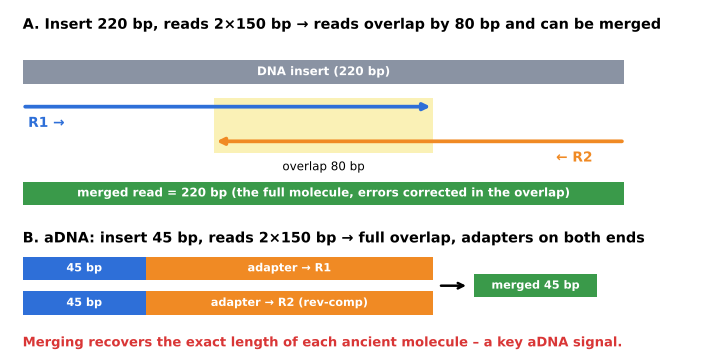</p>

### Background: the poly-G problem

<p align="center">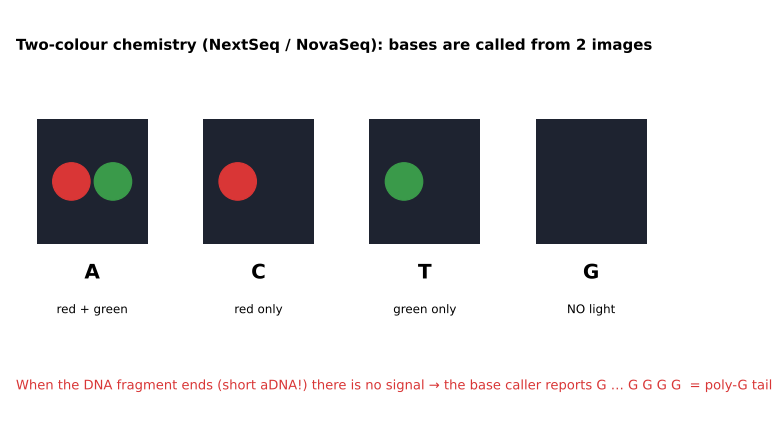</p>

NovaSeq and NextSeq instruments use **two-colour chemistry**: G is the base that emits **no light**. When the molecule has already ended – which happens all the time with short aDNA – the sensor sees darkness and calls a long run of high-quality `GGGGGG…`. These **poly-G tails** are not in the genome and must be removed. fastp detects NovaSeq/NextSeq data from the read headers and enables poly-G trimming automatically; it can be forced with `-g` (`--trim_poly_g`).

### The data
For demonstration we use a **modern** paired-end metagenome (an infant stool sample, G65860) from the [DIABIMMUNE project](https://diabimmune.broadinstitute.org/diabimmune/three-country-cohort/resources/metagenomic-sequence-data). Colab machines have internet access, so `wget` downloads the two files (R1 and R2) directly. `-q` = quiet, `-nc` (*no-clobber*) = don't download again if the file is already there.

In [ ]:
%%bash
cd "$WORKDIR"
mkdir -p 03_FASTP_PE && cd 03_FASTP_PE
wget -q -nc https://diabimmune.broadinstitute.org/diabimmune/data/16/G65860_pe_1.fastq.gz
wget -q -nc https://diabimmune.broadinstitute.org/diabimmune/data/16/G65860_pe_2.fastq.gz
ls -lh
zcat G65860_pe_1.fastq.gz | head -n 4

### Run fastp

| Flag | Meaning |
|---|---|
| `--in1`, `--in2` | input R1 and R2 |
| `-p` | `--overrepresentation_analysis`: report over-represented sequences (like FastQC) |
| `-c` | `--correction`: correct mismatched bases in the overlap of a pair, using the base with the higher quality |
| `--merge` | merge overlapping pairs into single reads |
| `--merged_out=…` | file for the merged reads (pairs that could not be merged are discarded unless `--out1/--out2` are given) |
| `-h …html`, `-j …json` | the HTML report for humans and the JSON report for programs |
| `-w $THREADS` | number of **w**orker threads (the original command used 20 on a big server; Colab has 2) |
| `-l 30` | `--length_required`: discard reads shorter than 30 bp (same as `-m 30` in cutadapt) |

fastp detects adapters automatically in PE mode by looking at the overlap of R1 and R2, so we don't need to give the adapter sequence.

In [ ]:
%%bash
cd "$WORKDIR"/03_FASTP_PE
fastp --in1 G65860_pe_1.fastq.gz --in2 G65860_pe_2.fastq.gz -p -c \
      --merge --merged_out=G65860.trimmed_merged.fastq.gz \
      -h G65860_fastp_report.html -j G65860_fastp_report.json \
      -w $THREADS -l 30

fastp prints a summary to the screen (*standard error*). Now let's open the full HTML report:

In [ ]:
show_html("03_FASTP_PE/G65860_fastp_report.html", height=900)

The JSON report contains the same numbers in machine-readable form. Let's extract the key ones and plot the **insert-size distribution**, which fastp estimates from the overlap of each pair. Insert size will matter again for **de-novo assembly** at the end of the course.

In [ ]:
fp = json.load(open("03_FASTP_PE/G65860_fastp_report.json"))
s  = fp["summary"]
fr = fp.get("filtering_result", {})
display(pd.Series({
    "reads before filtering":  s["before_filtering"]["total_reads"],
    "reads after filtering":   s["after_filtering"]["total_reads"],
    "Q30 rate before (%)":     round(100 * s["before_filtering"]["q30_rate"], 1),
    "Q30 rate after (%)":      round(100 * s["after_filtering"]["q30_rate"], 1),
    "low quality reads":       fr.get("low_quality_reads"),
    "too short reads":         fr.get("too_short_reads"),
    "duplication rate (%)":    round(100 * fp.get("duplication", {}).get("rate", float("nan")), 1),
    "insert size peak (bp)":   fp["insert_size"]["peak"],
    "pairs w/o overlap (insert size unknown)": fp["insert_size"].get("unknown"),
}, name="G65860").to_frame())

hist = np.array(fp["insert_size"]["histogram"])
plt.figure(figsize=(9, 3.5))
plt.bar(np.arange(len(hist)), hist, width=1, color="#F08A24")
plt.xlabel("Insert size (bp)"); plt.ylabel("Read pairs"); plt.title("G65860 insert-size distribution (fastp)")
plt.xlim(0, len(hist)); plt.show()

❓ **Questions**
1. What is the peak insert size? Is it shorter or longer than the read length? What does that mean for how many pairs could be merged?
2. How does the fastp report compare with FastQC/MultiQC? Which information does fastp give that FastQC does not?
3. This is a *modern* stool sample. How would you expect the insert-size distribution of an *ancient* sample to look?
4. Does the report show poly-G trimming? Look at the read headers printed above: which instrument produced these reads (hint: HiSeq uses four-colour chemistry)?

<details><summary><b>Optional: the extended fastp command used in many aDNA pipelines</b></summary>

```bash
fastp --in1 R1.fastq.gz --in2 R2.fastq.gz \
      --merge --merged_out merged.fastq.gz \
      --out1 unmerged_R1.fastq.gz --out2 unmerged_R2.fastq.gz \   # keep the pairs that did not merge
      --detect_adapter_for_pe -g -c -l 30 -y \                    # -g force poly-G trimming, -y low-complexity filter
      -h report.html -j report.json -w $THREADS
```
`-y` (`--low_complexity_filter`) removes reads such as `ATATATATAT…` or `AAAAAA…`, which are a common source of false-positive classifications.
</details>

---
## 5. Host DNA removal

### Background
Even in environmental samples (sediments, permafrost) **human DNA** is almost always present – from people who excavated, handled or processed the sample. In host-associated studies (dental calculus, coprolites, bones) the host fraction is usually even the largest one. Removing it is good practice for three reasons:

* **Scientific:** human reads that remain in the data can be misclassified as microbes, because many microbial reference genomes in public databases contain fragments of human sequence (and vice versa). This is not a theoretical problem – a high-profile *Nature* paper linking tumour microbiomes to cancer was **retracted** partly because of insufficient removal of human reads ([Retraction Watch, 2024](https://retractionwatch.com/2024/06/26/all-authors-agree-to-retraction-of-nature-article-linking-microbial-dna-to-cancer/)).
* **Computational:** fewer reads → faster taxonomic profiling (Day 2).
* **Ethical / legal:** human reads are personal genetic data. Many journals and data repositories (and the GDPR in the EU) require them to be removed before raw data are made public.

The approach is simple: **align all reads to the human reference genome and keep only the reads that do *not* align.**

<p align="center">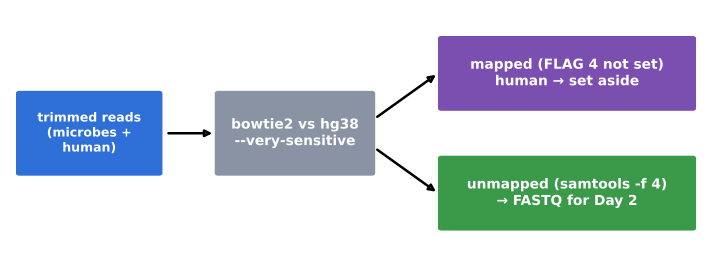</p>

### Tools
**Bowtie2** is a fast short-read aligner. Before aligning, the reference genome must be *indexed* (a compressed searchable data structure, the FM-index). Indexing the 3 Gbp human genome takes hours and >16 GB RAM, so it has been done for you:

```bash
# DO NOT RUN THIS (ALREADY DONE): download and index the human reference genome
# wget http://hgdownload.soe.ucsc.edu/goldenpath/hg38/bigZips/hg38.fa.gz
# bowtie2-build --large-index hg38.fa.gz hg38.fa.gz --threads 20
```

**samtools** reads and manipulates alignment files. Bowtie2 writes alignments in the text **SAM** format; we immediately convert them to the compressed binary **BAM** format.

### The commands, explained

| Command / flag | Meaning |
|---|---|
| `bowtie2 -x $HG38_INDEX` | the index **prefix** (the index files are `hg38.fa.gz.1.bt2l`, `….2.bt2l`, …) |
| `--end-to-end` | the **whole** read must align; no soft-clipping of read ends (the alternative `--local` may clip ends). For short aDNA reads, end-to-end mode avoids spurious partial alignments |
| `--very-sensitive` | the slowest, most thorough preset (more and shorter seeds, more re-seeding). We want to catch **every** human read, even damaged ones |
| `--threads $THREADS` | CPU cores |
| `-U <file>` | the **u**npaired (single-end) reads to align |
| `\| samtools view -bS -h -@ $THREADS -` | the pipe sends the SAM text into samtools: `-b` output BAM, `-S` input is SAM (auto-detected in modern samtools), `-h` keep the header, `-@` extra threads, `-` = read from the pipe |
| `samtools sort` | order alignments by chromosome and position (needed for indexing and IGV) |
| `samtools index` | create the `.bai` index for fast random access |
| `samtools view -b -f 4` | keep only reads **with** FLAG bit 4 set = **unmapped** reads (`-F 4` would do the opposite: mapped reads only) |
| `samtools bam2fq … \| gzip` | convert the unmapped reads back to FASTQ (`bam2fq` is an alias of `samtools fastq`) and compress |

> 💡 **SAM FLAG** is a number in column 2 of every alignment whose bits encode properties of the read: 1 = paired, 4 = **unmapped**, 16 = reverse strand, 256 = secondary alignment, 1024 = PCR duplicate, … You can decode any flag at [broadinstitute.github.io/picard/explain-flags.html](https://broadinstitute.github.io/picard/explain-flags.html).

This step is the **slowest of the day** (aligning all samples to a 3 Gbp genome with 2 cores) – a good moment for a coffee or for the questions above.

In [ ]:
%%bash
cd "$WORKDIR"
mkdir -p 04_HOST_REMOVAL

# stop early with a clear message if the index or the trimmed reads are missing
ls "${HG38_INDEX}".1.bt2* > /dev/null 2>&1 || { echo "❌ hg38 Bowtie2 index not found: '$HG38_INDEX' – check the paths cell"; exit 1; }

for sample in $(cat SAMPLES.txt); do
    [ -s 03_TRIMMED/${sample}.trimmed.fastq.gz ] || { echo "❌ 03_TRIMMED/${sample}.trimmed.fastq.gz missing – run Section 3 first"; exit 1; }
    echo "$(date +%H:%M:%S)  aligning ${sample} to hg38 ..."

    # 1. align trimmed reads to the human genome, convert SAM -> BAM on the fly
    bowtie2 -x "$HG38_INDEX" --end-to-end --threads $THREADS --very-sensitive \
            -U 03_TRIMMED/${sample}.trimmed.fastq.gz 2> 04_HOST_REMOVAL/${sample}_bowtie2.log \
    | samtools view -bS -h -@ $THREADS - > 04_HOST_REMOVAL/${sample}_aligned_to_hg38.bam

    # stop if Bowtie2 failed (e.g. index or memory problem) instead of producing empty files
    [ -s 04_HOST_REMOVAL/${sample}_aligned_to_hg38.bam ] || { echo "❌ Bowtie2 failed for ${sample}:"; cat 04_HOST_REMOVAL/${sample}_bowtie2.log; exit 1; }

    # 2. sort and index the alignments
    samtools sort 04_HOST_REMOVAL/${sample}_aligned_to_hg38.bam -@ $THREADS \
        > 04_HOST_REMOVAL/${sample}_aligned_to_hg38.sorted.bam
    samtools index 04_HOST_REMOVAL/${sample}_aligned_to_hg38.sorted.bam

    # 3. keep only the reads that did NOT align to the human genome (FLAG 4)
    samtools view -b -f 4 04_HOST_REMOVAL/${sample}_aligned_to_hg38.sorted.bam \
        > 04_HOST_REMOVAL/${sample}_unaligned_to_hg38.bam

    # 4. convert the human-free reads back to FASTQ for Day 2
    samtools bam2fq 04_HOST_REMOVAL/${sample}_unaligned_to_hg38.bam | gzip \
        > 04_HOST_REMOVAL/${sample}_unaligned_to_hg38.fastq.gz

    # the unsorted BAM is no longer needed
    rm 04_HOST_REMOVAL/${sample}_aligned_to_hg38.bam
done
ls -lh 04_HOST_REMOVAL

Two small additions compared to the original course commands: `2> …_bowtie2.log` saves Bowtie2's alignment summary (Bowtie2 writes it to *standard error*, stream number 2), and the intermediate unsorted BAM is deleted to save Drive space.

> 💡 **For your own projects:** if you only need the human-free FASTQ, you can skip sorting and indexing and do it in a single pass: `bowtie2 … | samtools fastq -f 4 - | gzip > clean.fastq.gz`, or let Bowtie2 write them directly with `--un-gz clean.fastq.gz`. We keep the sorted BAM today because we want to *look* at the human alignments.

### How much human DNA was in each sample?

Bowtie2's log reports the overall alignment rate. Let's collect it and count the reads with `samtools view -c` (`-c` = **c**ount instead of printing; `-F 4` = mapped reads only, `-f 4` = unmapped only). Bowtie2 reports only one alignment per read by default, so there are no secondary alignments to double-count.

In [ ]:
%%bash
cd "$WORKDIR"
echo -e "sample\ttotal\thuman\tnon_human" > 04_HOST_REMOVAL/host_removal_summary.tsv
for sample in $(cat SAMPLES.txt); do
    bam=04_HOST_REMOVAL/${sample}_aligned_to_hg38.sorted.bam
    total=$(samtools view -c $bam)
    human=$(samtools view -c -F 4 $bam)
    nonhuman=$(samtools view -c -f 4 $bam)
    echo -e "${sample}\t${total}\t${human}\t${nonhuman}" >> 04_HOST_REMOVAL/host_removal_summary.tsv
done
cat 04_HOST_REMOVAL/host_removal_summary.tsv
echo; echo "Bowtie2 summary for sample1:"; cat 04_HOST_REMOVAL/sample1_bowtie2.log

In [ ]:
host = pd.read_csv("04_HOST_REMOVAL/host_removal_summary.tsv", sep="\t", index_col=0)
host["pct_human"] = (100 * host.human / host.total).round(2)
display(host)

host["pct_human"].plot.bar(figsize=(9, 3.5), color="#7B4FB0")
plt.ylabel("% reads aligned to hg38"); plt.title("Human DNA content per sample"); plt.show()

❓ **Questions**
1. Which samples contain the most human DNA?
2. Would you trust a microbial species whose reads are only found in the *human-aligned* fraction? Why might a few microbial reads still align to hg38?

### Looking at human alignments in IGV

The [**Integrative Genomics Viewer (IGV)**](https://igv.org/) shows reads stacked against the reference genome. `igv-notebook` embeds IGV directly into the notebook:

* `igv_notebook.init()` – loads the IGV JavaScript into the notebook,
* `igv_notebook.Browser({...})` – creates a browser with a reference genome (`"hg38"` is downloaded from IGV's public genome server) and a starting locus,
* `b.load_track({...})` – adds our BAM file as an alignment track; `"path"` points to a local file and `"indexPath"` to its `.bai` index.

> 💡 **Two practical notes on IGV in Colab.** (1) IGV reads files through the notebook, and reading them **directly from Google Drive** fails, so the helper `igv_local()` first **copies** the files it needs (BAM with its `.bai` index, FASTA with its `.fai` index) to Colab's local disk (`/content/igv`). (2) IGV takes **10–20 seconds** to appear the first time – wait before concluding that it is empty.

We automatically jump to the region of the first human read of the sample with the most human DNA. Try zooming out, scrolling, and clicking on a read to see its details (mapping quality, CIGAR, mismatches). Mismatches are coloured; can you see **C→T** mismatches near read ends?

In [ ]:
import os, shutil, igv_notebook

def igv_local(*paths, folder="/content/igv"):
    """Copy files (BAM + .bai, FASTA + .fai, BED, …) from Google Drive to Colab's local disk
    and return their new paths – IGV cannot read them reliably straight from Drive."""
    os.makedirs(folder, exist_ok=True)
    return [shutil.copy(p, os.path.join(folder, os.path.basename(p))) for p in paths]

igv_notebook.init()

top = host["human"].idxmax()
bam = f"{WORKDIR}/04_HOST_REMOVAL/{top}_aligned_to_hg38.sorted.bam"

first = subprocess.run(f"samtools view -F 4 '{bam}' | head -n 1", shell=True,
                       capture_output=True, text=True).stdout.split("\t")
if len(first) > 3:
    chrom, pos = first[2], int(first[3])
    locus = f"{chrom}:{max(1, pos - 100)}-{pos + 200}"
    print(f"Showing {top} at {locus}")
    bam_l, bai_l = igv_local(bam, bam + ".bai")
    b = igv_notebook.Browser({"genome": "hg38", "locus": locus})
    b.load_track({"name": f"{top} vs hg38", "path": bam_l, "indexPath": bai_l,
                  "format": "bam", "type": "alignment"})
else:
    print("No reads aligned to hg38 in any sample – nothing to show.")

> 💡 To see where the human reads are concentrated, run `samtools idxstats <bam>` (reads per chromosome) and type another locus (e.g. `chrM`, the mitochondrial genome, which is present in many copies per cell and is often the best-covered human sequence in aDNA) into the IGV search box.

---
## 6. Read filtering summary: how many reads survived each step?

Every pre-processing step removes reads. For your Methods section – and to spot problematic samples – you should always report how many reads were left after each step. Let's combine the cutadapt table and the host-removal table:

In [ ]:
funnel = pd.DataFrame({
    "raw":            cut["reads_in"],
    "after cutadapt": cut["reads_out"],
    "non-human":      host["non_human"],
})
display(funnel.assign(pct_kept=(100 * funnel["non-human"] / funnel["raw"]).round(1)))

(funnel / 1e3).plot.bar(figsize=(11, 4), color=["#8A93A3", "#2E6FD8", "#3A9A4A"], width=0.8)
plt.ylabel("Reads (thousands)"); plt.title("Reads remaining after each pre-processing step")
plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

funnel.to_csv("04_HOST_REMOVAL/read_filtering_summary.tsv", sep="\t")

❓ Which step removes the most reads? Is any sample left with so few reads that you would be worried about analysing it further?

---
## Summary

Today we learned that:

* aDNA molecules are **short**, so raw reads contain a lot of **adapter** – QC reports that look "bad" by modern standards are expected and must be interpreted with aDNA in mind,
* **cutadapt** removes adapters, trims low-quality ends and filters out reads that are too short to be classified reliably; its logs must be kept and reported,
* after trimming, **read length = molecule length**, one of our first signals of ancient origin,
* **fastp** merges overlapping paired-end reads (recovering the full molecule) and removes **poly-G** artefacts of two-colour chemistry,
* **host (human) DNA** is removed by aligning to hg38 and keeping the **unmapped** reads (`samtools view -f 4`),
* every step should be tracked in a **read-filtering summary**.

The human-free reads in **`04_HOST_REMOVAL/*_unaligned_to_hg38.fastq.gz`** are the input for **Day 2: taxonomic profiling**. They are saved in your Drive, so nothing needs to be re-run tomorrow.

## Questions to think about

1. Why does adapter read-through occur more often in ancient than in modern DNA libraries?
2. What are the risks of choosing a minimum read length that is too low – or too high – for aDNA?
3. Why should we *not* aggressively error-correct or trim the ends of aDNA reads?
4. What information does merging paired-end reads give us that single-end sequencing does not?
5. Why is removing human DNA important even for a sediment sample?

## Resources

* FastQC: [bioinformatics.babraham.ac.uk/projects/fastqc](https://www.bioinformatics.babraham.ac.uk/projects/fastqc)
* MultiQC: Ewels P. et al. (2016) *Bioinformatics* 32:3047–3048, [doi:10.1093/bioinformatics/btw354](https://doi.org/10.1093/bioinformatics/btw354)
* cutadapt: Martin M. (2011) *EMBnet.journal* 17:10–12, [doi:10.14806/ej.17.1.200](https://doi.org/10.14806/ej.17.1.200)
* fastp: Chen S. et al. (2018) *Bioinformatics* 34:i884–i890, [doi:10.1093/bioinformatics/bty560](https://doi.org/10.1093/bioinformatics/bty560)
* Bowtie2: Langmead B. & Salzberg S. (2012) *Nat Methods* 9:357–359, [doi:10.1038/nmeth.1923](https://doi.org/10.1038/nmeth.1923)
* samtools: Li H. et al. (2009) *Bioinformatics* 25:2078–2079, [doi:10.1093/bioinformatics/btp352](https://doi.org/10.1093/bioinformatics/btp352)
* igv-notebook: [github.com/igvteam/igv-notebook](https://github.com/igvteam/igv-notebook)
* gargammel: Renaud G. et al. (2017) *Bioinformatics* 33:577–579, [doi:10.1093/bioinformatics/btw670](https://doi.org/10.1093/bioinformatics/btw670)
* aMeta: Pochon Z. et al. (2023), [doi:10.1101/2022.10.03.510579](https://doi.org/10.1101/2022.10.03.510579)

---
## Save this notebook as HTML

Finally, export the notebook – with all its outputs – to a single **HTML file** that you can open in any browser, keep as a record of your work, or share. [`jupyter nbconvert`](https://nbconvert.readthedocs.io/) converts the notebook file (`.ipynb`) to other formats; `--to html` selects HTML, and `--output-dir` writes the result into your own working folder (you cannot write into the instructor's shared folder).

1. **Save the notebook first** (*File ▸ Save*, or Ctrl/Cmd + S): nbconvert converts the file as it is stored in Google Drive.
2. Run the cell below. It looks for `Day1_QC_shortcut.ipynb` in your Drive (if you opened the notebook from GitHub, use *File ▸ Save a copy in Drive* first, or set `NB_PATH` by hand).

Interactive elements that need a running Colab session – embedded reports served by `show_html()` and IGV views – appear empty in the HTML file; tables, plots and printed output are kept.

In [ ]:
import glob, os, shutil, subprocess, sys
NB_NAME = "Day1_QC_shortcut.ipynb"
NB_PATH = None   # <- set by hand if the search below does not find the notebook

if NB_PATH is None:
    pats = [f"/content/drive/MyDrive/{NB_NAME}", f"/content/drive/MyDrive/*/{NB_NAME}",
            f"/content/drive/MyDrive/*/*/{NB_NAME}"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    NB_PATH = max(hits, key=os.path.getmtime) if hits else None     # the most recently saved copy

OUT_DIR = os.environ.get("WORKDIR", "/content/drive/MyDrive/AEMG01")
if NB_PATH:
    print("converting", NB_PATH)
    # convert a local copy: nbconvert cannot cope with spaces in the path (e.g. "… (1)" shortcuts)
    os.makedirs("/content/nb_export", exist_ok=True)
    local_nb = shutil.copy(NB_PATH, f"/content/nb_export/{NB_NAME}")
    args = ["--to", "html", local_nb, "--output-dir", OUT_DIR]
    # use the `jupyter` command if it exists, otherwise nbconvert as a Python module
    cmd = ["jupyter", "nbconvert"] + args if shutil.which("jupyter") else [sys.executable, "-m", "nbconvert"] + args
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0 and "No module named nbconvert" in r.stderr:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nbconvert"])
        r = subprocess.run([sys.executable, "-m", "nbconvert"] + args, capture_output=True, text=True)
    print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout)
    html = os.path.join(OUT_DIR, NB_NAME.replace(".ipynb", ".html"))
    print(("✅ HTML file: " if os.path.exists(html) else "❌ conversion failed – see the message above: ") + html)
else:
    print(f"{NB_NAME} not found in your Drive – save a copy in Drive (File ▸ Save a copy in Drive) or set NB_PATH")